# 12.0 — Advanced movement research foundation and feasibility

**Part 1 · Research question.** Which athletes, observations and speed states support each Milestone 12 method (12A–12F), and on which shared grids, cohorts and folds will every method be compared?

**Part 2 · Hypothesis.** None — an inventory. Every later notebook reads this notebook's manifest (`m12_foundation_manifest.json`) and refuses to run on other grids.

**Reused, never rebuilt.** Milestone 11 foundation (`discovery_v1`: officials, attempt / athlete features, NFL targets, folds, envelopes) and the NFL acceleration–speed histograms `m11_envelope_hist` (athlete × game × 0.5 yd/s × 0.25 yd/s² frame counts — the NFL observations of 12A / 12C / 12E; scanned lazily, never fully loaded). The only new pass is over the Combine frames (bounded: one drill family at a time) to build per-attempt a(v) curves, speed–time curves and histograms on the SAME edges as the NFL histograms.

**Execution.** Run cells in order. `RUN_MODE = 'smoke'` needs the Milestone 11 smoke artifacts; smoke numbers are wiring checks, never results.

In [1]:
RUN_MODE = 'full'
SEED = 20261015
FORCE_REBUILD = False        # True = rebuild the Combine curve tables even when persisted
SAVE_TABLES = True
SAVE_FIGURES = True
NUM_WORKERS = 0
MEMORY_BUDGET_GB = 6.0       # displayed against the estimated in-memory sizes below

In [2]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)

import numpy as np
import polars as pl
from IPython.display import Markdown, display

from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement.artifacts import ResearchStore
from nflbdb.research.advanced_movement.m11 import config as m11c
from nflbdb.research.advanced_movement.m11 import sources as src
from nflbdb.research.advanced_movement.m12 import advanced_evaluation as ae
from nflbdb.research.advanced_movement.m12 import config as m12c
from nflbdb.research.advanced_movement.m12 import figures as fg
from nflbdb.research.advanced_movement.m12 import foundation as fd
from nflbdb.research.advanced_movement.m12 import reporting as rp
from nflbdb.research.advanced_movement.m12 import shared_movement_encoder as se
from nflbdb.research.advanced_movement.m12 import validation as v12

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES, save_tables=SAVE_TABLES,
                                seed=SEED, num_workers=NUM_WORKERS).validate()
store = ResearchStore(cfg, controls)
amc.seed_everything(controls.seed)
C = m12c.M12Config().for_mode(controls)
S = src.M11Sources(cfg, store, m11c.M11Config().for_mode(controls))
D = fd.M12Data(store, C, S)
PROV = m12c.provenance('12.0', controls, C)
W = store.write_frame
label = 'SMOKE — wiring check, numbers are not results' if controls.smoke else 'FULL'
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · config `{C.hash()}`'))
display(store.describe())

**Run mode: `full`** (FULL) · config `c2903a12f8449fa2`

what,where
str,str
"""run mode""","""full"""
"""tables (CSV)""","""reports/tables/advanced_moveme…"
"""datasets (Parquet + schema sid…","""warehouse/gold/advanced_moveme…"
"""figures (PNG 300 DPI, SVG, PDF…","""reports/figures/advanced_movem…"
"""models and fitted preprocessin…","""artifacts/models/advanced_move…"


In [3]:

import inspect
import traceback

from nflbdb.research.advanced_movement.m12 import validation as v12

FAILED_CHECKS = [
    "check_grouped_folds_and_leakage",
    "check_simex_and_em_recovery",
    "check_missing_view_factor_model",
]

for name in FAILED_CHECKS:
    print("\n" + "=" * 90)
    print(name)
    print("=" * 90)

    fn = getattr(v12, name, None)

    if fn is None:
        print("Function not found; inspect validation.py for its actual name.")
        continue

    try:
        print(inspect.getsource(fn))
    except (OSError, TypeError):
        print("Source unavailable through inspect.")

    print("\n--- FAILURE TRACEBACK ---")

    try:
        fn()
    except Exception:
        traceback.print_exc()



check_grouped_folds_and_leakage
def check_grouped_folds_and_leakage() -> str:
    d = _frame()
    d = d.with_columns(pl.col("fold").cast(pl.Int64))
    bad = pl.concat([d, d.filter(pl.col("nfl_id") == 3).with_columns(pl.lit(1, dtype=pl.Int64).alias("fold"))])
    bad = bad.with_columns(pl.when((pl.col("nfl_id") == 3) & (pl.col("fold") != 1)).then(pl.lit(4, dtype=pl.Int64)).otherwise(pl.col("fold")).alias("fold"))
    try:
        ae.oof_ladder(bad, "y", {"M": ae.Model(["x"])}, C, 0)
    except LeakageError:
        pass
    else:
        raise AssertionError("an athlete in two folds must raise LeakageError")
    return "athlete-grouped folds enforced (an athlete in two folds raises)"


--- FAILURE TRACEBACK ---

check_simex_and_em_recovery
def check_simex_and_em_recovery() -> str:
    s = me.Scenario("t", 0.4, 2, 0.4, n=500)
    long, ath, bt = me.simulate(s, np.random.default_rng(5))
    st = me.athlete_stats(long)
    d = ath.join(st.select("nfl_id", "xbar", "n_att"), on="nfl_id")


In [4]:
# synthetic software checks of every Milestone 12 module (software only — never evidence about athletes)
checks = v12.run_all(v12.ALL_CHECKS)
with pl.Config(tbl_rows=-1, fmt_str_lengths=120):
    display(checks)
v12.assert_all_passed(checks)

C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\src\nflbdb\research\advanced_movement\m12\distributional_capacity.py:212: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(M, 0)
C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\src\nflbdb\research\advanced_movement\m12\distributional_capacity.py:213: RuntimeWarning: Degrees of freedom <= 0 for slice.
  tau2 = np.maximum(np.nanvar(M, 0) - np.nanmean(S2, 0), 0.0)
C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\src\nflbdb\research\advanced_movement\m12\distributional_capacity.py:213: RuntimeWarning: Mean of empty slice
  tau2 = np.maximum(np.nanvar(M, 0) - np.nanmean(S2, 0), 0.0)


check,status,detail
str,str,str
"""grouped_folds_and_leakage""","""PASS""","""athlete-grouped folds enforced (an athlete in two folds raises)"""
"""block_sees_training_only""","""PASS""","""fold-fitted blocks receive one held-out fold; held-out labels never change held-out predictions"""
"""common_cohort_pairing""","""PASS""","""every model of a ladder is scored on the identical athletes (paired)"""
"""bootstrap_unit_and_seed""","""PASS""","""athlete bootstrap deterministic by seed; Spearman–Brown, Holm and Benjamini–Hochberg exact"""
"""checkpoint_resume_safety""","""PASS""","""completion gate blocks partial runs; a checkpoint of another definition is refused"""
"""evidence_tier_rules""","""PASS""","""evidence tiers never promote on a point estimate; interval readings exact"""
"""spline_basis_and_support""","""PASS""","""B-spline partition of unity, zero outside support; P-spline fit; only short interior gaps bridged"""
"""fpca_recovery_and_isolation""","""PASS""","""FPCA recovers planted components; partial curves scored; fold-fitted FPCA ignores held-out curves"""
"""combine_curve_interpolation""","""PASS""","""Combine a(v) at bin mid-speeds: every crossed bin supported at 10 Hz, exact on a ramp, no extrapolation, gaps > 1 yd/s n…"


## Part 3 · Data, memory plan and Combine curve tables

The NFL histogram is scanned lazily (only counts are aggregated here). The Combine pass reads one drill family at a time (quality `reject` excluded, longest valid segment per attempt — the Milestone 11 rule). Forty attempts give the rising-phase a(v) curve (onset → first frame of peak speed; no bin outside it) and the speed–time curve from onset (only when the onset is recorded; NaN after the recording ends).

In [5]:
off, folds, aidx, env = D.officials(), D.folds(), D.attempt_index(), D.envelopes()
hist = D.hist()
hist_rows = int(hist.select(pl.len()).collect().item())
hist_mb = ae.file_mb(store.discovery.data_dir / 'm11_envelope_hist.parquet')
plan = ae.memory_plan([
    {'item': 'm11_envelope_hist (lazy; aggregated only)', 'n_rows': hist_rows, 'n_cols': 6, 'bytes_per_value': 4, 'on_disk_mb': hist_mb,
     'note': 'never materialised in 12.0'},
    {'item': 'Combine frames of the largest family (one at a time)', 'n_rows': int(aidx['n_frames'].sum()), 'n_cols': 25, 'bytes_per_value': 8,
     'note': 'upper bound: all families together'},
    {'item': 'm12_combine_hist (attempt × speed × accel cells)', 'n_rows': int(aidx.height * 120), 'n_cols': 6, 'bytes_per_value': 8, 'note': 'estimate'}],
    MEMORY_BUDGET_GB)
display(plan)
print(f'{off.height} Combine registry athletes · {aidx.height} tracked attempts · {hist_rows:,} NFL histogram cells')

item,n_rows,n_cols,est_mb,on_disk_mb,note,budget_mb,within_budget
str,i64,i64,f64,f64,str,f64,bool
"""m11_envelope_hist (lazy; aggre…",3033611,6,72.8,10.5,"""never materialised in 12.0""",6000.0,true
"""Combine frames of the largest …",431094,25,86.2,null,"""upper bound: all families toge…",6000.0,true
"""m12_combine_hist (attempt × sp…",757200,6,36.3,null,"""estimate""",6000.0,true


510 Combine registry athletes · 6310 tracked attempts · 3,033,611 NFL histogram cells


In [6]:
NAMES = ['m12_combine_curves', 'm12_combine_speed_time', 'm12_combine_hist', 'm12_combine_quality']
if all(store.has(n) for n in NAMES) and not FORCE_REBUILD:
    comb = {n: store.read_frame(n, fd.NB['12.0']) for n in NAMES}
    print('Combine curve tables restored from this run mode')
else:
    comb = fd.combine_tables(S, C, list(src.FAMILY_ORDER))
    for n, d in comb.items():
        W(d, n, csv=n != 'm12_combine_hist')
curves, st, chist, qual = (comb[n] for n in NAMES)
nsup = fd.nfl_bin_support(hist)
nsum = fd.nfl_athlete_summary(hist)
gts = fd.game_top_speed(D.episodes())
W(nsup, 'm12_nfl_bin_support')
W(gts, 'm12_game_top_speed')
qsum = qual.group_by('family').agg(pl.len().alias('attempts'), pl.col('nfl_id').n_unique().alias('athletes'), pl.col('median_dt').median(),
                                   pl.col('irregular_share').mean(), pl.col('onset_censored').mean().alias('onset_censored_share'),
                                   pl.col('peak_at_last_frame').mean().alias('peak_at_last_frame_share'), pl.col('duration_s').median()).sort('family')
W(qsum, 'm12_tracking_quality')
display(Markdown('**Tracking quality per drill family** (sampling: median Δt; censoring: onset outside the recording; observation length: median duration).'))
display(qsum)

Combine curve tables restored from this run mode


**Tracking quality per drill family** (sampling: median Δt; censoring: onset outside the recording; observation length: median duration).

family,attempts,athletes,median_dt,irregular_share,onset_censored_share,peak_at_last_frame_share,duration_s
str,u32,u32,f64,f64,f64,f64,f64
"""backpedal_transition""",732,183,0.1,0.0,0.036885,0.407104,7.9
"""forty""",793,418,0.1,0.0,0.081967,0.281211,5.0
"""gauntlet""",404,267,0.1,0.0,0.009901,0.274752,9.15
"""other""",2713,510,0.1,0.0,0.040546,0.347954,6.5
"""pass_rush""",819,239,0.1,0.0,0.068376,0.626374,4.8
"""short_shuttle""",223,170,0.1,0.0,0.174888,0.816143,5.0
"""three_cone""",626,299,0.1,0.0,0.202875,0.840256,5.3


## Part 4 · Physical definitions — grids, shared speed range, cohorts and folds

Units: speed yd/s, tangential acceleration yd/s², time s, distance yd. Grids reuse the Milestone 11 envelope edges exactly (no re-binning of NFL data). The **shared speed range** is the longest contiguous run of 0.5 yd/s bins in which at least `shared_support_share` of linked athletes are supported in BOTH domains (NFL ≥ `min_frames_bin_nfl` frames over ≥ 2 games; Combine ≥ `min_frames_bin_combine` rising-phase frames). It is decided by support counts only — no outcome value. Folds are the Milestone 11 athlete folds (Milestone 06 folds inside them).

In [7]:
linked = sorted(set(off['nfl_id'].to_list()) & set(nsum['nfl_id'].to_list()) & set(folds['nfl_id'].to_list()))
sup_tab, shared = fd.shared_speed_support(nsup, curves, linked, C)
grids = fd.movement_grids(C, shared)
reg = fd.cohort_registry(off, folds, aidx, curves, nsum, nsup, env, gts, shared, C)
avail = fd.availability(reg, shared, se.TORCH, C)
fman = folds.with_columns(pl.lit(ae.fold_signature(folds)).alias('fold_signature'), pl.lit(C.hash()).alias('config_hash'))
W(sup_tab, 'm12_shared_speed_support')
W(grids, 'm12_movement_grids')
W(reg, 'm12_cohort_registry')
W(avail, 'm12_experiment_availability')
W(fman, 'm12_fold_manifest')
if controls.save_tables:
    store.write_json('m12_dependency_manifest', fd.dependency_manifest())
    store.write_json('m12_foundation_manifest', fd.foundation_manifest(C, reg, folds, grids, shared))
print(f"linked athletes: {len(linked)} · shared speed range: {shared.get('lo')} – {shared.get('hi')} yd/s ({len(shared.get('bins', []))} bins) · rule: {shared.get('rule')}")
with pl.Config(tbl_rows=-1, tbl_width_chars=240, fmt_str_lengths=80):
    display(grids)
    display(avail)

linked athletes: 401 · shared speed range: 1.0 – 7.0 yd/s (12 bins) · rule: longest contiguous run of bins with share_both ≥ 0.6 among 401 linked athletes


grid_id,variable,unit,lo,hi,step,n_points,support_rule
str,str,str,f64,f64,f64,i64,str
"""speed""","""speed""","""yd/s""",0.0,11.5,0.5,23,"""NFL bin ≥ 40 frames over ≥ 2 games; Combine bin mid-speed inside the monotone ri…"
"""speed_shared""","""speed""","""yd/s""",1.0,7.0,0.5,12,"""longest contiguous run of bins with share_both ≥ 0.6 among 401 linked athletes"""
"""tangential_accel""","""a_tan""","""yd/s²""",-8.0,8.0,0.25,64,"""same edges as m11_envelope_hist; values outside are clipped into the edge bins (…"
"""time_from_onset""","""t""","""s""",0.0,4.0,0.1,41,"""forty only, onset recorded (first speed < 1.0 yd/s); NaN after the recording end…"
"""curvature""","""a_n / v²""","""1/yd""",null,null,null,0,"""NOT gridded: lateral acceleration is not in the NFL histograms; used only by 12F…"
"""heading_change""","""Δheading""","""deg""",0.0,180.0,45.0,4,"""09A redirection episodes with valid heading; Combine transitions with turn speed…"
"""distance""","""path distance""","""yd""",0.0,40.0,5.0,8,"""forty only, from onset; reported for orientation (12A phase analysis)"""


track,eligible_athletes,repeat_observations,repeat_unit,supported_positions,linked_athletes,missing_variables,expected_scale,existing_artifacts,new_computation,feasibility
str,i64,i64,str,str,i64,str,str,str,str,str
"""12C""",267,7592,"""NFL games (distribution splits)""","""DB, DL, OL, WR""",267,"""play context (down, alignment) is not in the histograms""","""≈ athletes × 23 × 64 histogram cells""","""m11_envelope_hist, m11_envelopes, 09A episodes""","""quantile curves, game-split reliability, ladder M0–M6""","""ready"""
"""12B""",297,594,"""forty attempts""","""DB, DL, OL, WR""",297,"""only 1–3 attempts per athlete""","""small""","""m11_attempt_features, m11_repeatability""","""variance components, RC, SIMEX, EM, synthetic grid""","""ready"""
"""12A""",310,586,"""forty attempts""","""DB, DL, OL, WR""",310,"""""","""small""","""m12_combine_curves, m11_envelope_hist""","""splines, FPCA, function-on-function, elastic alignment""","""gated_on_upstream"""
"""12D""",510,2086,"""drill families""","""DB, DL, OL, TE, WR""",401,"""drill participation depends on position""","""small""","""m11_attempt_features, m11_athlete_features""","""missing-data factor models""","""ready"""
"""12E""",267,6365,"""NFL games""","""DB, DL, OL, WR""",267,"""Combine forty has few frames per speed bin""","""athletes² × bins² for Sinkhorn (bounded)""","""m12_combine_hist, m11_envelope_hist""","""Sinkhorn / sliced / conditional OT, bootstrap""","""ready"""
"""12F""",510,793,"""Combine attempts""","""DB, DL, OL, TE, WR""",401,"""""","""≤ 200k windows × 48 × 6 float32 ≈ 0.23 GB""","""m11 representation code; NFL windows NOT yet extracted""","""one tracking scan for windows + encoder training""","""ready"""


## Part 5–8 · Baselines, method readiness and uncertainty of the inventory

No model is fitted here. Baselines are declared once for every track (`advanced_evaluation`): **M0** position + draft year · **M1** M0 + height, weight, official forty, 10-yd split (the Milestone 11 M1) · **M1+** adds official three-cone / short shuttle (sensitivity only). Counts are of athletes (the independent unit), never frames.

In [8]:
with pl.Config(tbl_rows=-1, tbl_width_chars=260, fmt_str_lengths=200):
    display(pl.DataFrame(m12c.track_table()).select('track', 'primary_outcome', 'primary_comparison', 'evaluation_target', 'depends_on'))
pos_counts = (reg.filter(pl.col('in_combine')).unpivot(index=['nfl_id', 'position_group'], on=[c for c in reg.columns if c.startswith('elig_')], variable_name='track', value_name='eligible')
              .filter(pl.col('eligible')).group_by('position_group', 'track').len().rename({'len': 'n_athletes'}))
W(pos_counts, 'm12_position_support')
display(pos_counts.pivot(on='track', index='position_group', values='n_athletes').sort('position_group'))

track,primary_outcome,primary_comparison,evaluation_target,depends_on
str,str,str,str,str
"""12.0""","""—""","""—""","""measurement_reliability""",""""""
"""12C""","""nfl.q90_shared (estimator frozen by the declared reliability rule before any Combine value is joined); secondary nfl.game_top_speed_q75""","""M3 vs M1 on the primary target; M2 vs M1 on the secondary target (Holm over the two)""","""cross_domain_physical_transfer""","""12.0"""
"""12B""","""corrected vs naive standardized coefficient of each preregistered feature on its matched NFL target""","""regression calibration (B1) vs naive (B0) held-out Δ RMSE; SIMEX / EM coefficients descriptive""","""cross_domain_physical_transfer""","""12.0"""
"""12A""","""athlete-mean integrated squared error over each athlete's supported shared speed bins""","""A2 (M1 + FPCA scores) vs A0 (M1 + scalar bands)""","""cross_domain_physical_transfer""","""12.0, 12C"""
"""12D""","""test–retest correlation of factor scores (attempt-split) vs best single feature""","""D3 structured multi-view FA vs best single feature""","""measurement_reliability""","""12.0"""
"""12E""","""cross-domain retrieval AUC within position""","""E5 conditional OT vs E0 Euclidean features (paired athlete bootstrap)""","""cross_domain_physical_transfer""","""12.0"""
"""12F""","""inductive cross-domain retrieval AUC; Δ RMSE on the 12C primary target""","""F4 vs F0 engineered and vs random encoder""","""cross_domain_physical_transfer""","""12.0, 12C"""
"""12G""","""Δ RMSE vs M1 on the 12C primary target, identical athletes""","""each available method vs M1""","""cross_domain_physical_transfer""","""12.0, 12C, 12B, 12A, 12D, 12E, 12F"""


position_group,elig_12C_nfl,elig_12E,elig_12A,elig_12F,elig_12D,elig_12B,elig_12C_transfer
str,u32,u32,u32,u32,u32,u32,u32
"""DB""",71,60,75,122,122,75,60
"""DL""",79,63,75,118,118,69,63
"""OL""",68,56,63,121,121,64,56
"""TE""",28,24,25,42,42,26,24
"""WR""",70,64,72,107,107,63,64


## Part 9 · Figures

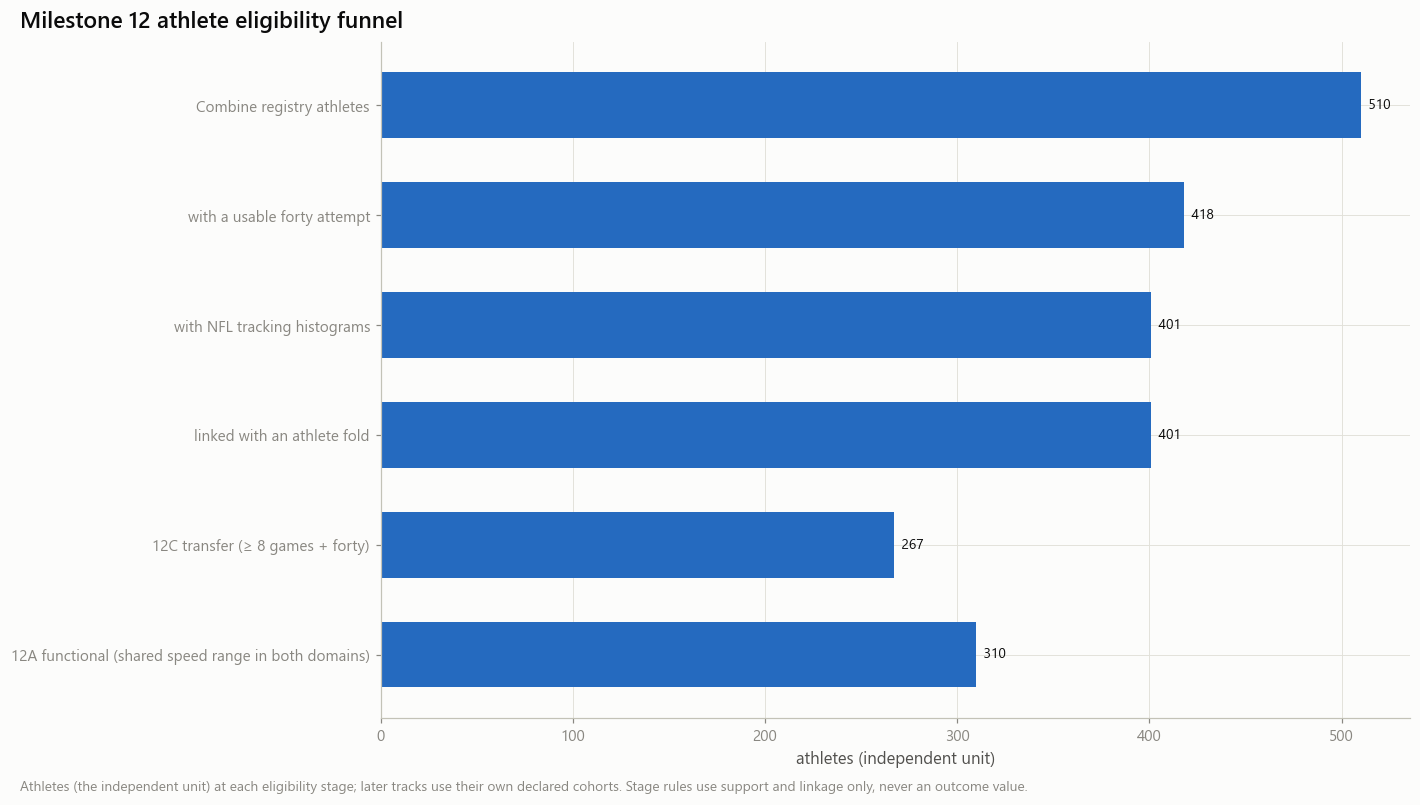

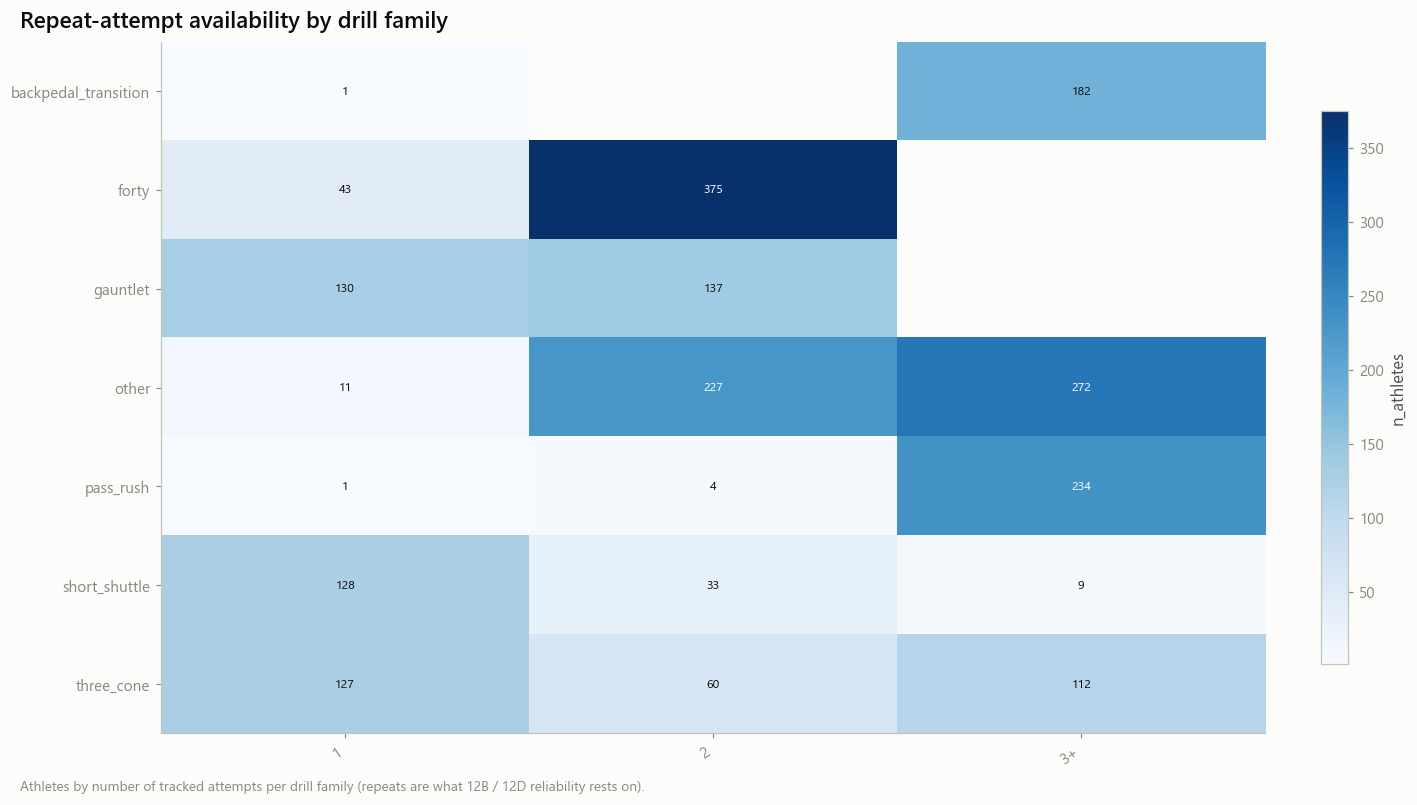

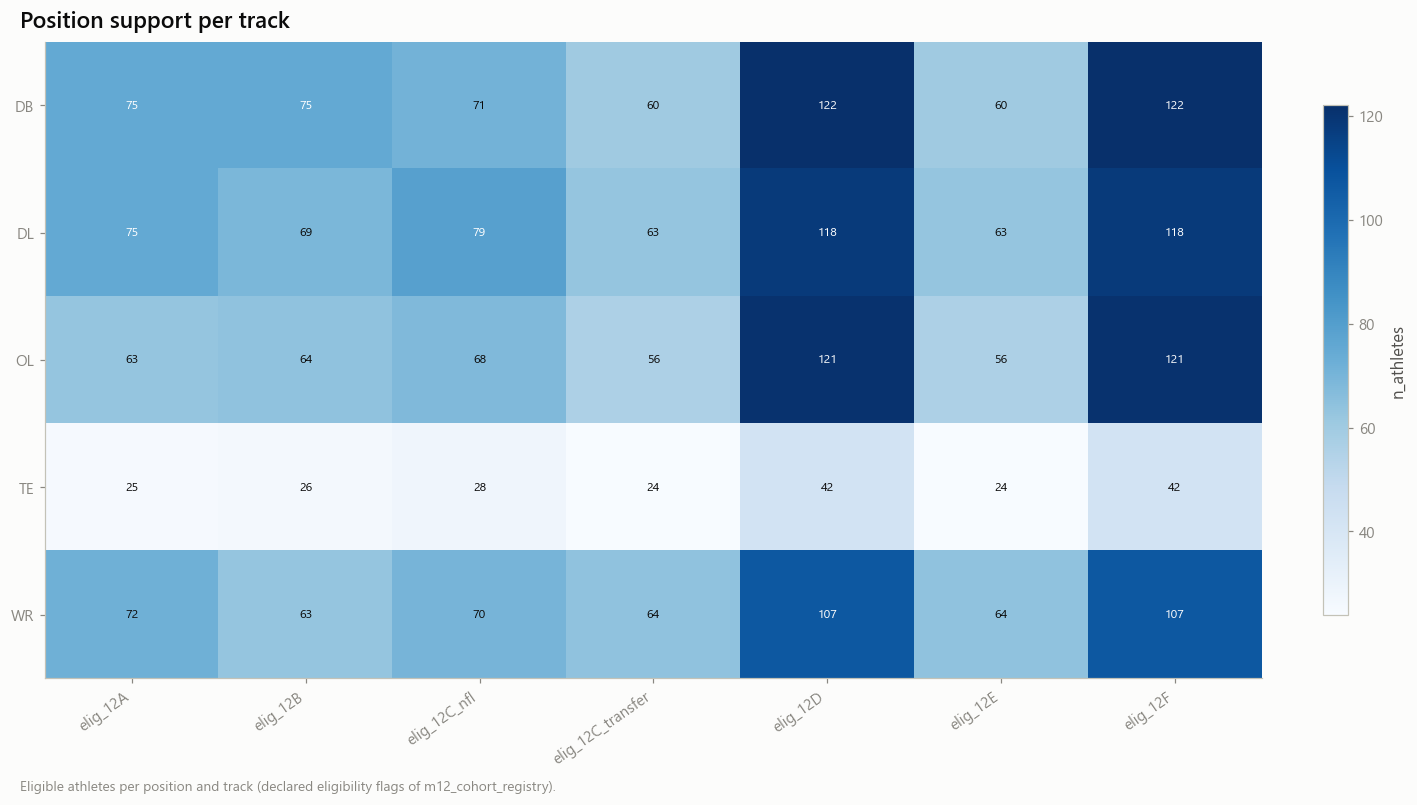

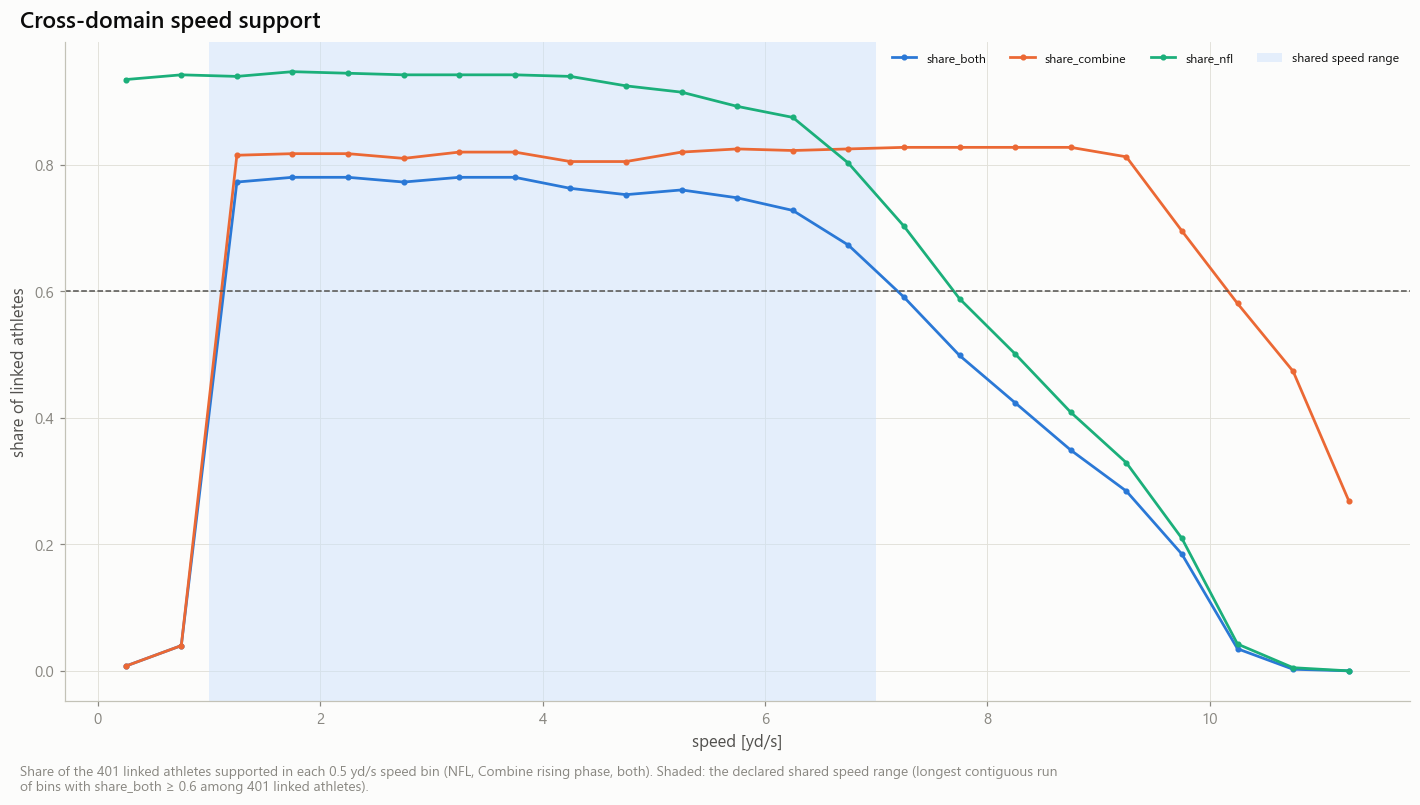

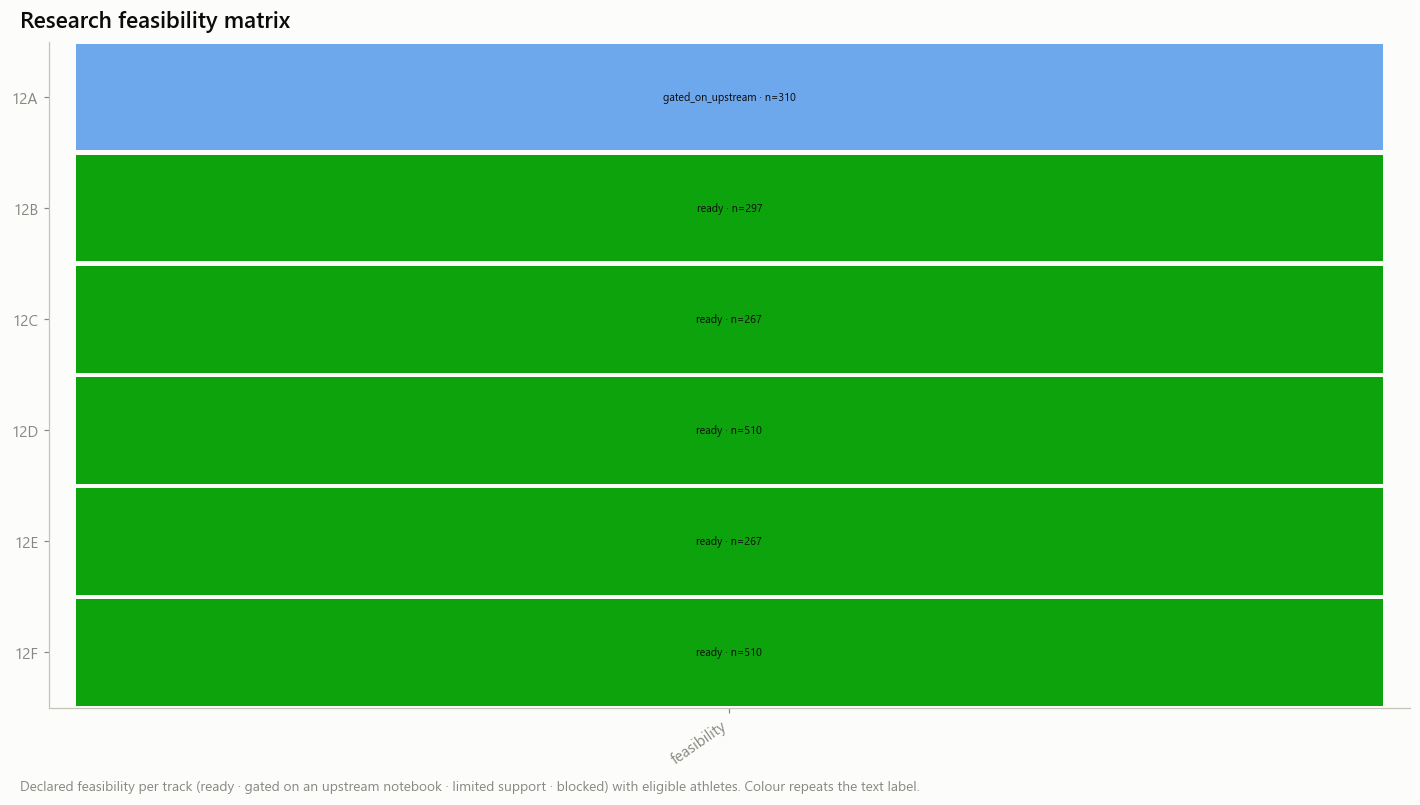

In [9]:
funnel = pl.DataFrame([
    {'stage': 'Combine registry athletes', 'n_athletes': int(reg['in_combine'].sum())},
    {'stage': 'with a usable forty attempt', 'n_athletes': int(reg['has_forty'].sum())},
    {'stage': 'with NFL tracking histograms', 'n_athletes': int((reg['in_combine'] & reg['in_nfl']).sum())},
    {'stage': 'linked with an athlete fold', 'n_athletes': int(reg['linked'].sum())},
    {'stage': f'12C transfer (≥ {C.min_games_athlete} games + forty)', 'n_athletes': int(reg['elig_12C_transfer'].sum())},
    {'stage': '12A functional (shared speed range in both domains)', 'n_athletes': int(reg['elig_12A'].sum())}])
store.show(fg.fig_funnel(funnel, 'Milestone 12 athlete eligibility funnel', 'Athletes (the independent unit) at each eligibility stage; later tracks use their own declared cohorts. Stage rules use support and linkage only, never an outcome value.'),
           'AM12_0_01_eligibility_funnel', {'funnel': funnel}, publication=True, source='m12_cohort_registry', n=f"{int(reg['in_combine'].sum())} athletes")
rep_ = (aidx.group_by('nfl_id', 'family').len().with_columns(pl.when(pl.col('len') >= 3).then(pl.lit('3+')).otherwise(pl.col('len').cast(pl.String)).alias('attempts'))
        .group_by('family', 'attempts').len().rename({'len': 'n_athletes'}))
store.show(fg.fig_heatmap(rep_, 'family', 'attempts', 'n_athletes', 'Repeat-attempt availability by drill family', 'Athletes by number of tracked attempts per drill family (repeats are what 12B / 12D reliability rests on).'),
           'AM12_0_02_repeat_availability', {'repeats': rep_}, source='m11_attempt_index')
store.show(fg.fig_heatmap(pos_counts, 'position_group', 'track', 'n_athletes', 'Position support per track', 'Eligible athletes per position and track (declared eligibility flags of m12_cohort_registry).'),
           'AM12_0_03_position_support', {'position_support': pos_counts}, source='m12_cohort_registry')
sl = sup_tab.with_columns(((pl.col('speed_lo') + pl.col('speed_hi')) / 2).alias('speed')).unpivot(index='speed', on=['share_nfl', 'share_combine', 'share_both'], variable_name='domain', value_name='share')
store.show(fg.fig_lines(sl, 'speed', 'share', 'domain', 'Cross-domain speed support', f"Share of the {len(linked)} linked athletes supported in each 0.5 yd/s speed bin (NFL, Combine rising phase, both). Shaded: the declared shared speed range ({shared.get('rule')}).",
                        'speed [yd/s]', 'share of linked athletes', ref=C.shared_support_share, shade=(shared.get('lo', np.nan), shared.get('hi', np.nan))),
           'AM12_0_04_cross_domain_speed_support', {'support': sup_tab}, publication=True, source='m12_shared_speed_support + m12_combine_curves', n=f'{len(linked)} linked athletes')
fm_ = avail.select('track', pl.lit('feasibility').alias('aspect'), 'feasibility', (pl.col('feasibility') + ' · n=' + pl.col('eligible_athletes').cast(pl.String)).alias('label'))
store.show(fg.fig_state_grid(fm_, 'track', 'aspect', 'feasibility', fg.STATUS_COLORS, 'Research feasibility matrix', 'Declared feasibility per track (ready · gated on an upstream notebook · limited support · blocked) with eligible athletes. Colour repeats the text label.', label='label'),
           'AM12_0_05_feasibility_matrix', {'availability': avail}, publication=True, source='m12_experiment_availability')

## Part 10–12 · Conclusions, persisted artifacts, next questions

In [10]:
status = m12c.EXECUTED
facts = {'status': status, 'run_mode': controls.run_mode,
         'sample': f"{int(reg['in_combine'].sum())} Combine athletes, {aidx.height} tracked attempts; {nsum.height} NFL athletes in the histograms; {len(linked)} linked.",
         'evidence': [f"shared speed range {shared.get('lo')}–{shared.get('hi')} yd/s ({len(shared.get('bins', []))} bins)"]
                     + [f"{r['track']}: {r['eligible_athletes']} eligible athletes, feasibility {r['feasibility']}" + (f" ({r['missing_variables']})" if r['missing_variables'] else '') for r in avail.iter_rows(named=True)],
         'alternatives': ['Drill participation and NFL exposure depend on position and role: eligibility counts describe who was observed, not prospects in general.'],
         'relevance': 'Fixes, before any advanced model runs, which athletes and speed states each method may use.',
         'limitations': ['NFL histograms carry game and season, not down / alignment / role.', 'The shared-range rule is a declared support threshold, not a measurement.'],
         'next': ['Run 12C (distributional NFL capacity) — the highest-priority track.']}
md = rp.conclusion_markdown('12.0', facts)
display(Markdown(md))
rp.write_conclusion(store, '12.0', md)
block = '### Track registry (declared before execution)' + chr(10) + chr(10) + rp.md_table(pl.DataFrame(m12c.track_table()), ['track', 'primary_outcome', 'primary_comparison', 'evaluation_target']) \
        + chr(10) + '### Feasibility (12.0, executed)' + chr(10) + chr(10) + rp.md_table(avail, ['track', 'eligible_athletes', 'linked_athletes', 'supported_positions', 'feasibility', 'missing_variables'])
rp.update_doc(store, 'EXPERIMENT_REGISTRY.md', block)
OUT = ['m12_combine_curves', 'm12_combine_speed_time', 'm12_combine_hist', 'm12_combine_quality', 'm12_nfl_bin_support', 'm12_game_top_speed', 'm12_cohort_registry',
       'm12_movement_grids', 'm12_shared_speed_support', 'm12_fold_manifest', 'm12_experiment_availability', 'm12_tracking_quality', 'm12_position_support']
rp.run_manifest(store, '12.0', PROV, OUT, status, {'shared_speed': shared, 'n_linked': len(linked)})
print('Send back: the checks table, the memory plan, the quality table, the grids and availability tables, the funnel figure.')
print('Next: 12c_distributional_nfl_movement_capacity.ipynb')

## 12.0 — conclusion (executed; run mode full; generated 2026-10-15T00:37:51Z)

### Research question
Which athletes, observations and speed states support each advanced method?

### Declared primary hypothesis
Not a test: inventory, grids, folds and feasibility.

### Primary outcome / comparison
— — — (evaluation target: `measurement_reliability`)

### Sample
510 Combine athletes, 6310 tracked attempts; 401 NFL athletes in the histograms; 401 linked.

### Main evidence (from persisted tables)
- shared speed range 1.0–7.0 yd/s (12 bins)
- 12C: 267 eligible athletes, feasibility ready (play context (down, alignment) is not in the histograms)
- 12B: 297 eligible athletes, feasibility ready (only 1–3 attempts per athlete)
- 12A: 310 eligible athletes, feasibility gated_on_upstream
- 12D: 510 eligible athletes, feasibility ready (drill participation depends on position)
- 12E: 267 eligible athletes, feasibility ready (Combine forty has few frames per speed bin)
- 12F: 510 eligible athletes, feasibility ready

### Alternative explanations
- Drill participation and NFL exposure depend on position and role: eligibility counts describe who was observed, not prospects in general.

### Practical interpretation
Fixes, before any advanced model runs, which athletes and speed states each method may use.

### Limitations
- NFL histograms carry game and season, not down / alignment / role.
- The shared-range rule is a declared support threshold, not a measurement.

### Next research questions
- Run 12C (distributional NFL capacity) — the highest-priority track.


Send back: the checks table, the memory plan, the quality table, the grids and availability tables, the funnel figure.
Next: 12c_distributional_nfl_movement_capacity.ipynb
